In [1]:
import pandas as pd
df = pd.read_csv('Synthetic_Car_Prices_10000.csv')

In [2]:
df.head()

,age,mileage_10k,engine_l,power_10hp,accident,full_service,price_pln
0,1,7,1.2,11,1,0,58014
1,10,4,2.5,13,1,1,47279
2,8,10,1.6,22,0,1,68040
3,5,12,2.5,8,1,1,49508
4,5,5,2.0,8,1,0,58299


In [3]:
X = df.drop(columns=['price_pln'])
y = df['price_pln']

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
from sklearn.linear_model import LinearRegression

In [6]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[-54001.85,-25395.31, 12347.08, 32485.65,-11266.42, 5118.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.824e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[44.81,44.65,31.58,27.84,27.49,27.19]"


In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE: {mse:.2f} PLN^2 ")
print(f"RMSE: {rmse:.2f} PLN")
print(f"MAE:  {mae:.2f} PLN")
print(f"R^2:   {r2:.4f}")

MSE: 50988749.85 PLN^2 
RMSE: 7140.64 PLN
MAE:  5653.76 PLN
R^2:   0.9055


In [8]:
print(f"Intercept: {model.intercept_}")

coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
print(coef_df)

Intercept: 88238.82289056267
        Feature   Coefficient
0           age -54001.845554
1   mileage_10k -25395.306073
2      engine_l  12347.082008
3    power_10hp  32485.652411
4      accident -11266.422977
5  full_service   5118.196912


C:\Users\artem\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


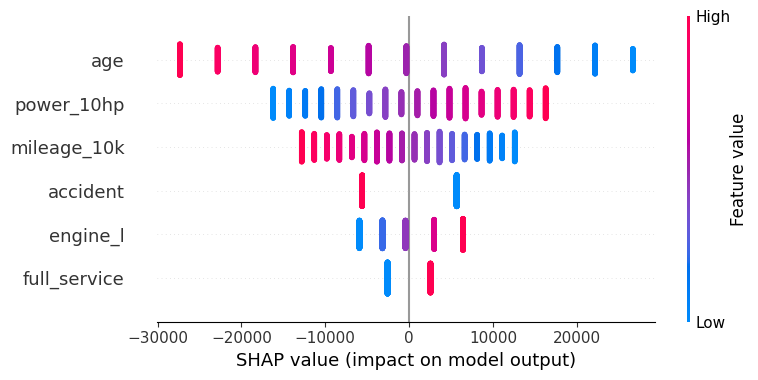

In [9]:
import shap

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

masker = shap.maskers.Independent(X_train_scaled_df, max_samples=8000)
explainer = shap.Explainer(model, masker)
shap_values = explainer(X_test_scaled_df)

shap.summary_plot(shap_values, X_test_scaled_df)

In [10]:
y_pred[0:10]

array([82560.41636799, 72808.82013344, 41040.83710877, 69121.73012894,
       45689.30968997, 72099.03460494, 33881.45903794, 75110.65343404,
       77220.10722225, 77599.57144205])

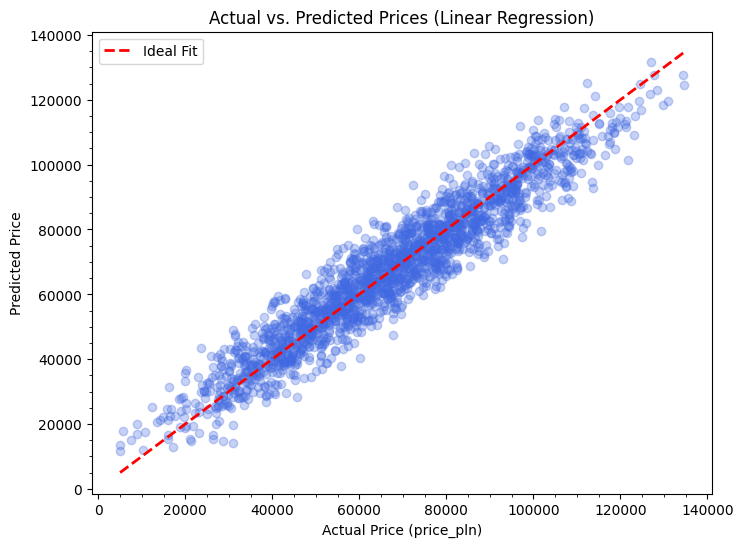

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='royalblue')

plt.minorticks_on()
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')

plt.xlabel("Actual Price (price_pln)")
plt.ylabel("Predicted Price")
plt.title("Actual vs. Predicted Prices (Linear Regression)")
plt.legend()
plt.show()

In [12]:
print(f"Predicted price: {y_pred[10]:.0f} PLN")
print(f"Actual price: {y_test.iloc[10]} PLN")

Predicted price: 74475 PLN
Actual price: 79438 PLN
